# SaringID — Indonesian SMS Scam Triage

**Track:** AI + Finance  
**User:** An Indonesian phone user deciding whether to trust an unexpected SMS.  
**Core job:** classify a message as **Normal**, **Potential fraud**, or **Promotion**, then explain the strongest text signals and advise caution.

> This is a hackathon prototype, not financial advice or a security guarantee. It must never be used as the sole reason to click a link, transfer money, reveal an OTP/PIN/password, or block a legitimate sender.

## What makes this more than a tutorial
1. A three-way distinction between normal messages, promotions, and fraud-like messages.
2. A fraud alert threshold tuned on a validation set, not the final test set.
3. A held-out test set, majority-class baseline, class-level metrics, and visible mistakes.
4. A separate, hand-written modern Indonesian stress-test set. Keep it out of training and clearly label it as synthetic.
5. An interactive demo that shows model scores and text features associated with the prediction.

**Important data note:** the linked Indonesian SMS corpus is older and should be treated as a historical benchmark, not as representative of every current WhatsApp, banking, or delivery scam. Before submission, verify the original dataset's usage terms. The original source repository does not make an explicit licence obvious in the project page; the hackathon asks teams to check dataset licences. If you cannot confirm permission, switch to a dataset with an explicit licence or use a dataset the organisers approve.


## 1. Install libraries

In [1]:
!pip -q install pandas scikit-learn matplotlib gradio

## 2. Load and inspect the public Indonesian SMS dataset

The CSV columns are `teks` (message) and `label`. The label mapping documented by the referenced project is `0 = Normal`, `1 = Fraud`, and `2 = Promotion`. Always inspect the file before trusting the mapping.

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    fbeta_score, classification_report, ConfusionMatrixDisplay
)

DATA_URL = "https://raw.githubusercontent.com/ksnugroho/klasifikasi-spam-sms/master/data/dataset_sms_spam_v1.csv"
LABEL_NAMES = {0: "Normal", 1: "Fraud", 2: "Promotion"}

raw = pd.read_csv(DATA_URL)
print("Columns:", raw.columns.tolist())
print("Rows before cleaning:", len(raw))
display(raw.head())

# Fail loudly if the source format changes; do not silently train on the wrong columns.
if not {"teks", "label"}.issubset(raw.columns):
    raise ValueError(f"Expected columns 'teks' and 'label'; found {raw.columns.tolist()}")

df = raw[["teks", "label"]].copy()
df = df.rename(columns={"teks": "text"})
df["text"] = df["text"].fillna("").astype(str).str.strip()
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)
df = df[(df["text"].str.len() > 0) & (df["label"].isin(LABEL_NAMES))].copy()

# Remove exact-text duplicates before splitting. If identical text has conflicting labels,
# exclude it rather than allowing ambiguous examples to leak across splits.
df["_norm"] = df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
conflict_norms = (
    df.groupby("_norm")["label"].nunique().loc[lambda s: s > 1].index
)
conflict_count = df["_norm"].isin(conflict_norms).sum()
df = df[~df["_norm"].isin(conflict_norms)].drop_duplicates("_norm").drop(columns="_norm")

print(f"Rows after cleaning: {len(df)}")
print(f"Conflicting duplicate rows excluded: {conflict_count}")
print("Class distribution:")
display(df["label"].map(LABEL_NAMES).value_counts().rename_axis("class").to_frame("count"))


Columns: ['teks', 'label']
Rows before cleaning: 1143


,teks,label
0,[PROMO] Beli paket Flash mulai 1GB di MY TELKO...,2
1,2.5 GB/30 hari hanya Rp 35 Ribu Spesial buat A...,2
2,"2016-07-08 11:47:11.Plg Yth, sisa kuota Flash ...",2
3,"2016-08-07 11:29:47.Plg Yth, sisa kuota Flash ...",2
4,4.5GB/30 hari hanya Rp 55 Ribu Spesial buat an...,2


Rows after cleaning: 1142
Conflicting duplicate rows excluded: 0
Class distribution:


,count
class,
Normal,568
Fraud,335
Promotion,239


## 3. Create train, validation, and test sets

- **Training set:** fit the text model.
- **Validation set:** choose the fraud-alert threshold.
- **Test set:** used once for the final comparison. Do not tune anything after looking at test results.

The split is stratified so each class is represented in each partition.

In [3]:
X = df["text"]
y = df["label"]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, random_state=42, stratify=y_trainval
)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")


Train: 730 | Validation: 183 | Test: 229


## 4. Train the AI model

TF-IDF converts words and two-word phrases into numeric features. Logistic regression learns which patterns are associated with each label. `class_weight="balanced"` helps when the labels are unevenly represented.

In [4]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=25000,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        C=2.0,
        random_state=42
    ))
])

model.fit(X_train, y_train)
print("Model trained.")
print("Classes learned:", model.named_steps["clf"].classes_)


Model trained.
Classes learned: [0 1 2]


## 5. Tune a fraud-alert threshold on validation data only

The model estimates a score for each class. For the fraud alert, we choose a threshold that maximises **F2** on validation data. F2 weights recall more than precision, reflecting that missing a scam can be costly. This does not make the model safe; it makes the trade-off explicit.

A message above the tuned fraud threshold becomes **Potential fraud**. Otherwise, it is assigned to whichever non-fraud class (Normal or Promotion) has the larger score.

Fraud threshold selected on validation set: 0.22
Best validation F2: 0.957


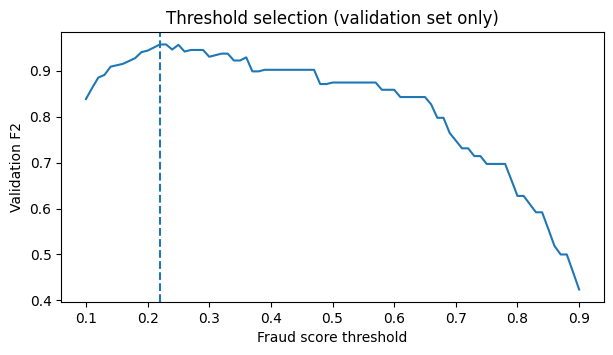

In [5]:
clf = model.named_steps["clf"]
classes = list(clf.classes_)
if 1 not in classes or 0 not in classes or 2 not in classes:
    raise ValueError(f"Expected all three labels 0, 1, 2 in training data; found {classes}")

fraud_idx = classes.index(1)
val_probs = model.predict_proba(X_val)
val_fraud_scores = val_probs[:, fraud_idx]
val_is_fraud = (y_val.to_numpy() == 1)

threshold_grid = np.arange(0.10, 0.91, 0.01)
threshold_scores = [
    fbeta_score(val_is_fraud, val_fraud_scores >= t, beta=2, zero_division=0)
    for t in threshold_grid
]
BEST_THRESHOLD = float(threshold_grid[int(np.argmax(threshold_scores))])
print(f"Fraud threshold selected on validation set: {BEST_THRESHOLD:.2f}")
print(f"Best validation F2: {max(threshold_scores):.3f}")

# Plot the validation-only threshold search so the decision is transparent.
plt.figure(figsize=(7, 3.5))
plt.plot(threshold_grid, threshold_scores)
plt.axvline(BEST_THRESHOLD, linestyle="--")
plt.xlabel("Fraud score threshold")
plt.ylabel("Validation F2")
plt.title("Threshold selection (validation set only)")
plt.show()


## 6. Define the triage policy and evaluate once on the held-out test set

We report accuracy, macro-F1, fraud precision, fraud recall, and fraud F2. Macro-F1 prevents the largest class from dominating the summary. Fraud precision and recall are especially important for a scam filter.

,System,Accuracy,Macro-F1,Fraud precision,Fraud recall,Fraud F2
0,Majority-class baseline,0.498,0.222,0.000,0.000,0.000
1,Always-normal baseline,0.498,0.222,0.000,0.000,0.000
2,SaringID model + validation threshold,0.917,0.903,0.831,0.955,0.928


Detailed test-set report:
              precision    recall  f1-score   support

      Normal       0.99      0.93      0.96       114
       Fraud       0.83      0.96      0.89        67
   Promotion       0.89      0.83      0.86        48

    accuracy                           0.92       229
   macro avg       0.90      0.91      0.90       229
weighted avg       0.92      0.92      0.92       229



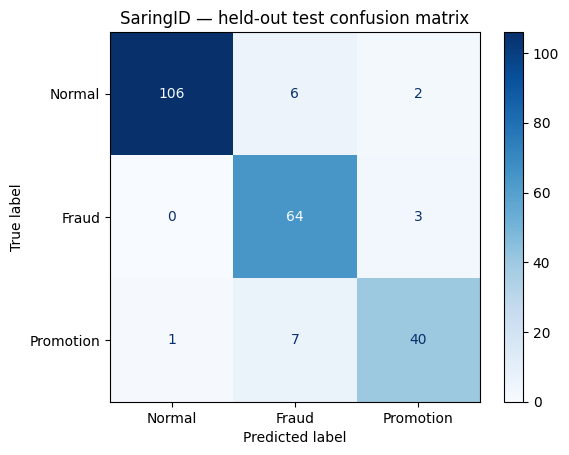

In [6]:
def apply_triage_policy(probabilities, threshold=BEST_THRESHOLD):
    """Convert 3-class probabilities into a fraud-first triage decision."""
    output = []
    nonfraud_ids = [i for i, label in enumerate(classes) if label != 1]
    for row in probabilities:
        if row[fraud_idx] >= threshold:
            output.append(1)
        else:
            best_nonfraud_position = int(np.argmax(row[nonfraud_ids]))
            output.append(classes[nonfraud_ids[best_nonfraud_position]])
    return np.asarray(output, dtype=int)


def metric_row(name, y_true, y_pred):
    y_true_fraud = (np.asarray(y_true) == 1)
    y_pred_fraud = (np.asarray(y_pred) == 1)
    return {
        "System": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Fraud precision": precision_score(y_true_fraud, y_pred_fraud, zero_division=0),
        "Fraud recall": recall_score(y_true_fraud, y_pred_fraud, zero_division=0),
        "Fraud F2": fbeta_score(y_true_fraud, y_pred_fraud, beta=2, zero_division=0)
    }

# Final predictions: the test set has not been used for model fitting or threshold selection.
test_probs = model.predict_proba(X_test)
y_pred = apply_triage_policy(test_probs)

# Simple baseline: always predict the most common class in the TRAINING data.
majority_label = int(y_train.mode().iloc[0])
y_pred_majority = np.full(len(y_test), majority_label, dtype=int)

# Optional second sanity baseline: always say "Normal". This catches no fraud by design.
y_pred_always_normal = np.zeros(len(y_test), dtype=int)

results = pd.DataFrame([
    metric_row("Majority-class baseline", y_test, y_pred_majority),
    metric_row("Always-normal baseline", y_test, y_pred_always_normal),
    metric_row("SaringID model + validation threshold", y_test, y_pred)
])
display(results.round(3))

print("Detailed test-set report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2],
    target_names=[LABEL_NAMES[i] for i in [0, 1, 2]],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1, 2],
    display_labels=[LABEL_NAMES[i] for i in [0, 1, 2]],
    cmap="Blues",
    values_format="d"
)
plt.title("SaringID — held-out test confusion matrix")
plt.show()


## 7. Show where the model fails

A credible project includes real mistakes from the held-out test set. Keep these examples in your write-up and explain plausible causes without pretending to know the cause for certain.

In [7]:
test_examples = pd.DataFrame({
    "message": X_test.to_numpy(),
    "actual": [LABEL_NAMES[int(v)] for v in y_test.to_numpy()],
    "predicted": [LABEL_NAMES[int(v)] for v in y_pred]
})

false_negatives = test_examples[(test_examples["actual"] == "Fraud") & (test_examples["predicted"] != "Fraud")]
false_positives = test_examples[(test_examples["actual"] != "Fraud") & (test_examples["predicted"] == "Fraud")]

print("FRAUD FALSE NEGATIVES — scams the model missed")
display(false_negatives.head(5))
print("FALSE POSITIVES — legitimate/promo messages flagged as fraud")
display(false_positives.head(5))


FRAUD FALSE NEGATIVES — scams the model missed


,message,actual,predicted
36,GRATIS internetan 5MB berlaku utk 7 hari hanya...,Fraud,Promotion
94,GRATIS 50 SMS ke sesame indosat selama 2 hari....,Fraud,Promotion
187,"Yuk Ikuti akun dakwah, caranya: ketik IKUT [sp...",Fraud,Promotion


FALSE POSITIVES — legitimate/promo messages flagged as fraud


,message,actual,predicted
39,"Baik Pak, berarti nanti Kamis kami ke kantor lagi",Normal,Fraud
44,"Segan baa lo ko wqwq hai di, gila kurus banget...",Normal,Fraud
52,Segera aktivasi rekening BTPN Wow! anda. Ketik...,Promotion,Fraud
88,Mau nonton bioskop gratis bersama keluarga? Ci...,Promotion,Fraud
89,Selamat!!anda telah mendapat gratis 200 sms da...,Promotion,Fraud


## 8. Your original contribution: modern Indonesian stress test

The historical public corpus may not cover today's delivery, e-wallet, marketplace, bank-impersonation, or OTP scams. Add **at least 20–30 messages written by your team** across all three categories. Make them synthetic; do not paste real people's private messages. Keep this set separate from training. It is a small challenge set, not a representative national benchmark.

In [8]:
# Starter examples — edit and expand these with messages your team writes.
# Labels: 0=Normal, 1=Fraud, 2=Promotion
stress_test = pd.DataFrame([
    ("Besok rapat OSIS jam 15.00 di aula, tolong bawa catatan ya.", 0),
    ("Ma, aku pulang agak terlambat. Nanti aku kabari lagi.", 0),
    ("Tolong kirim foto materi matematika halaman 32 kalau sempat.", 0),
    ("Terima kasih sudah membantu acara sekolah hari ini.", 0),
    ("Bank: akun Anda diblokir. Kirim PIN dan OTP melalui tautan ini sekarang.", 1),
    ("Paket Anda tertahan. Bayar biaya tambahan melalui tautan ini agar dikirim hari ini.", 1),
    ("Selamat Anda menang hadiah. Kirim kode OTP untuk mencairkan hadiah sekarang.", 1),
    ("Admin dompet digital: saldo akan hangus malam ini, login melalui link berikut.", 1),
    ("Promo akhir pekan: diskon 20 persen untuk menu pilihan sampai hari Minggu.", 2),
    ("Paket internet 10 GB berlaku 30 hari. Cek penawaran lewat aplikasi resmi operator.", 2),
    ("Diskon tiket bioskop setiap hari Selasa, syarat dan ketentuan berlaku.", 2),
    ("Promo makan siang hemat di gerai kami, tunjukkan pesan ini saat membayar.", 2),
], columns=["text", "label"])

stress_probs = model.predict_proba(stress_test["text"])
stress_pred = apply_triage_policy(stress_probs)
stress_test["actual"] = stress_test["label"].map(LABEL_NAMES)
stress_test["predicted"] = [LABEL_NAMES[int(v)] for v in stress_pred]
stress_test["fraud_score"] = stress_probs[:, fraud_idx]
display(stress_test[["text", "actual", "predicted", "fraud_score"]])

print("Synthetic stress-test report (do not mix this with the held-out public test score):")
print(classification_report(
    stress_test["label"], stress_pred,
    labels=[0, 1, 2],
    target_names=[LABEL_NAMES[i] for i in [0, 1, 2]],
    zero_division=0
))


,text,actual,predicted,fraud_score
0,"Besok rapat OSIS jam 15.00 di aula, tolong baw...",Normal,Normal,0.144581
1,"Ma, aku pulang agak terlambat. Nanti aku kabar...",Normal,Normal,0.035942
2,Tolong kirim foto materi matematika halaman 32...,Normal,Fraud,0.400759
3,Terima kasih sudah membantu acara sekolah hari...,Normal,Fraud,0.228715
4,Bank: akun Anda diblokir. Kirim PIN dan OTP me...,Fraud,Fraud,0.756138
5,Paket Anda tertahan. Bayar biaya tambahan mela...,Fraud,Fraud,0.242021
6,Selamat Anda menang hadiah. Kirim kode OTP unt...,Fraud,Fraud,0.690529
7,Admin dompet digital: saldo akan hangus malam ...,Fraud,Normal,0.208403
8,Promo akhir pekan: diskon 20 persen untuk menu...,Promotion,Promotion,0.206499
9,Paket internet 10 GB berlaku 30 hari. Cek pena...,Promotion,Promotion,0.073817


Synthetic stress-test report (do not mix this with the held-out public test score):
              precision    recall  f1-score   support

      Normal       0.67      0.50      0.57         4
       Fraud       0.50      0.75      0.60         4
   Promotion       1.00      0.75      0.86         4

    accuracy                           0.67        12
   macro avg       0.72      0.67      0.68        12
weighted avg       0.72      0.67      0.68        12



## 9. Explain the result with influential text features

The feature list shows which learned TF-IDF features pushed the selected class score upward. These are statistical associations, not proof that a message is fraudulent. The model can learn outdated patterns and be fooled by new ones.

In [9]:
def top_evidence_terms(text, predicted_label, top_n=6):
    vectorizer = model.named_steps["tfidf"]
    classifier = model.named_steps["clf"]
    class_position = list(classifier.classes_).index(int(predicted_label))
    row = vectorizer.transform([text])
    contributions = row.multiply(classifier.coef_[class_position]).toarray().ravel()
    names = vectorizer.get_feature_names_out()
    best_idx = np.argsort(contributions)[::-1]
    terms = [(names[i], float(contributions[i])) for i in best_idx if contributions[i] > 0][:top_n]
    return terms

for sample in [
    "Bank: akun Anda diblokir. Kirim PIN dan OTP melalui tautan ini sekarang.",
    "Besok rapat OSIS jam 15.00 di aula, tolong bawa catatan ya."
]:
    sample_probs = model.predict_proba([sample])[0]
    sample_pred = int(apply_triage_policy(sample_probs.reshape(1, -1))[0])
    print("\nMessage:", sample)
    print("Decision:", LABEL_NAMES[sample_pred])
    print("Class scores:", {LABEL_NAMES[c]: round(float(sample_probs[i]), 3) for i, c in enumerate(classes)})
    print("Top learned evidence:", top_evidence_terms(sample, sample_pred))



Message: Bank: akun Anda diblokir. Kirim PIN dan OTP melalui tautan ini sekarang.
Decision: Fraud
Class scores: {'Normal': 0.096, 'Fraud': 0.756, 'Promotion': 0.148}
Top learned evidence: [('pin', 0.5449320074839692), ('anda', 0.34991865631484415), ('kirim', 0.3034546818814063), ('bank', 0.27823817387806665), ('ini', 0.1906301355125964)]

Message: Besok rapat OSIS jam 15.00 di aula, tolong bawa catatan ya.
Decision: Normal
Class scores: {'Normal': 0.687, 'Fraud': 0.145, 'Promotion': 0.168}
Top learned evidence: [('ya', 0.280410579115984), ('jam', 0.2565021651837267), ('besok', 0.18795003974262514), ('bawa', 0.10822138375088253)]


## 10. Build the live demo

The interface accepts a message, shows the triage decision, reports the model's class scores, and lists influential features. Do not ask users to paste private messages or personal information into a public demo.

In [10]:
import gradio as gr


def analyze_message(text):
    text = (text or "").strip()
    if not text:
        return "Please enter a message.", "No message was analysed."

    probs = model.predict_proba([text])[0]
    pred = int(apply_triage_policy(probs.reshape(1, -1))[0])
    confidence = float(probs[classes.index(pred)])
    fraud_score = float(probs[fraud_idx])

    if pred == 1:
        decision = "⚠️ POTENTIAL FRAUD — pause and verify independently"
        action = "Do not click the link or share OTP/PIN/passwords. Contact the organisation using its official app or a phone number you already trust."
    elif pred == 2:
        decision = "PROMOTION / MARKETING — verify the sender"
        action = "A promotion is not automatically safe. Open the official app or website yourself rather than following an unexpected link."
    else:
        decision = "LIKELY NORMAL — still use caution"
        action = "The model did not identify strong fraud signals. This is not proof the sender is genuine."

    if confidence < 0.50:
        action = "LOW CONFIDENCE: ask a trusted person or verify through an official channel. " + action

    evidence = top_evidence_terms(text, pred)
    evidence_text = ", ".join([f"`{term}`" for term, _ in evidence]) if evidence else "No strong positive features were found."
    scores = "\n".join([f"- **{LABEL_NAMES[c]}:** {probs[i]:.1%}" for i, c in enumerate(classes)])
    report = (
        f"**Fraud score:** {fraud_score:.1%} (alert threshold: {BEST_THRESHOLD:.2f})\n\n"
        f"**Model class scores**\n{scores}\n\n"
        f"**Text features associated with this prediction:** {evidence_text}\n\n"
        f"**Suggested next step:** {action}\n\n"
        f"*Prototype only. Text features are correlations, not proof. Never share OTPs, PINs, or passwords.*"
    )
    return decision, report

app = gr.Interface(
    fn=analyze_message,
    inputs=gr.Textbox(lines=4, label="Paste a synthetic or non-sensitive message", placeholder="Type a message here..."),
    outputs=[gr.Textbox(label="Triage decision"), gr.Markdown(label="Scores, explanation, and safety guidance")],
    title="SaringID — Indonesian SMS Scam Triage",
    description="A prototype that distinguishes normal messages, promotions, and potential fraud. It is not a security guarantee."
)
app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4ab0514c1c086dd504.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
